# 06 · Storytelling — figuras finais e narrativa

**Objetivo.** Montar as figuras que vão para o `.pbix` e para o vídeo executivo e amarrar os
**quatro elementos obrigatórios** da narrativa: **Personagem · Ambiente · Conflito · Mensagem**.

Este notebook não descobre nada novo. Ele é o último da sequência justamente porque seu trabalho é
outro: pegar o que os notebooks 01–05 mediram e transformar em quatro imagens que uma pessoa
entende em dez segundos, sem legenda falada. É a diferença entre ter o número e conseguir defendê-lo
em frente à liderança.

| | |
|---|---|
| **Entradas** | `00_data/gold/base_analitica.csv` (n = 1.348) · `00_data/gold/reviews.csv` (9.255) · `00_data/silver/produtos.csv` (1.351) · `00_data/bronze/amazon.csv` (só contagem de linhas, **somente leitura**) |
| **Saídas** | `02_results/images/fig_st_01_arco_narrativo.png` · `fig_st_02_ambiente.png` · `fig_st_03_conflito.png` · `fig_st_04_mensagem.png` |
| **Formato** | slide 16:9 — 12,8 × 7,2 pol a 150 dpi = **1920 × 1080 px**, prontas para o vídeo |

### Os quatro elementos, e o número que prende cada um

| Elemento | Nesta análise | Número que o sustenta |
|---|---|---|
| **Personagem** | a **liderança** de sortimento e de preço — o herói é quem decide, **nunca a marca** | 1.348 produtos sob decisão |
| **Ambiente** | marketplace indiano, portfólio concentrado, sem variável de venda | 97,2% do portfólio em 3 famílias · valores em rupia, sem conversão (L5) |
| **Conflito** | **os arquétipos B e D descontam quase o mesmo e divergem em todo o resto** | 58% × 61% de desconto · 468 × 13.120 avaliações medianas · B é o único abaixo do limiar de satisfação (3,9) |
| **Mensagem** | se o desconto não separa os dois grupos, a decisão é de **sortimento e de vitrine** | 335 produtos em B · 19 em Q5 · 61 em Q6, de 187 no funil |

### Regras aplicadas aqui
- **T1** — todo ranking por nota usa `nota_corrigida` (Wilson), com o *n* ao lado.
- **T2** — nenhum grupo agregado com n < 30 é ranqueado; as 5 categorias abaixo do piso aparecem **agregadas e declaradas**, nunca ordenadas.
- **T3** — **toda figura traz fonte, base e *n* no rodapé.**
- **T4** — vedada linguagem causal: "associado a", nunca "causa".
- **T5** — magnitude sempre ao lado da significância.
- **T6** — `rating_count` é **volume de avaliações**; nunca venda, receita ou demanda.
- **T7** — `user_id` e `user_name` não existem nas camadas silver e gold; a ausência é verificada abaixo.
- **T8** — o corpus declara a unidade, deduplica por `review_id` e cita o truncamento em 8.
- **T9** — paleta v06 aplicada **por ferramenta** (`src/paleta.py`), no máximo 5 séries por visual.
- **L5** — valores monetários em rupia indiana, **sem símbolo e sem conversão**.

> As figuras `fig01`–`fig13` de `02_results/images/` são de outros notebooks e **não são
> sobrescritas** aqui. O prefixo `fig_st_` isola esta entrega.

## 1. Preparo

A primeira célula de código é sempre a mesma em todo notebook do projeto (`01_notebooks/README.md`):
a paleta entra **por ferramenta**. Cor escolhida à mão — no seletor, herdada de template — é
descumprimento de T9, e o motivo é prático: a rubrica avalia dashboard **e** vídeo; se os dois não
parecerem o mesmo produto, a inconsistência aparece antes de qualquer número.

O caminho `../src` só resolve se o notebook for executado a partir de `01_notebooks/`. Como ele
também é executado por `nbconvert` em automação, descobrimos a raiz procurando por `00_data/` e
reinserimos o caminho — assim a célula funciona nos dois casos em vez de falhar em um deles.

In [1]:
# Primeira célula obrigatória do projeto — T9: a paleta entra por ferramenta.
import sys; sys.path.insert(0, "../src")

import os

# Raiz do repositório, descoberta pela presença de 00_data/ (robusto ao diretório de execução).
_cwd = os.getcwd()
RAIZ = _cwd if os.path.isdir(os.path.join(_cwd, "00_data")) else os.path.dirname(_cwd)
if not os.path.isdir(os.path.join(RAIZ, "00_data")):
    raise FileNotFoundError(
        "Não encontrei 00_data/ a partir de " + _cwd +
        ". Execute este notebook de dentro do repositório (idealmente de 01_notebooks/).")
sys.path.insert(0, os.path.join(RAIZ, "src"))

%matplotlib inline
from IPython.display import Image, display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from paleta import aplicar, confere_visual, checar_series, CATEGORICA, CHAMADAS, ESTRUTURA, BASE

# tamanho_base maior que o padrão: estas figuras são lidas em slide e em vídeo,
# não em tela de notebook. A paleta é a mesma; só a tipografia cresce.
aplicar(tamanho_base=12)

# Tokens nomeados — nenhum hex escrito à mão neste notebook (T9).
AMBAR   = CATEGORICA[0]
AZUL    = CATEGORICA[1]
CLARA   = CATEGORICA[2]
LARANJA = CHAMADAS["atencao"]
TEAL    = CHAMADAS["favoravel"]
TINTA   = ESTRUTURA["tinta"]
SEC     = ESTRUTURA["secundario"]
GRADE   = ESTRUTURA["grade"]
CARD    = BASE["card"]
CANVAS  = BASE["canvas"]
DIVISOR = BASE["divisor"]

IMG = os.path.join(RAIZ, "02_results", "images")
os.makedirs(IMG, exist_ok=True)

SLIDE = (12.8, 7.2)   # 16:9 — a 150 dpi dá 1920 x 1080 px
DPI = 150
SEMENTE = 42
PISO = 30             # T2 — piso amostral de grupo agregado

print("paleta v06 aplicada ·", len(CATEGORICA), "cores categóricas · figuras em",
      f"{int(SLIDE[0]*DPI)}x{int(SLIDE[1]*DPI)} px")

paleta v06 aplicada · 6 cores categóricas · figuras em 1920x1080 px


### Funções de apoio

Quatro decisões ficam aqui, uma vez, em vez de repetidas em quatro figuras:

- `milhar` e `virg` — número no padrão brasileiro. Um slide com `13,120` em vez de `13.120` faz a
  liderança reler; releitura em vídeo é atrito.
- `quebrar` — quebra de linha calculada em **pontos**, não no olho. A 150 dpi, um título de 22 pt
  ocupa quase o dobro do que parece na tela; sem medir, o texto sai cortado na borda do slide. A
  largura média do caractere é estimada em 0,58 do corpo da fonte, que é a métrica da DejaVu Sans.
- `rodape` — **T3 numa função**. Toda figura chama; nenhuma figura sai sem fonte, base e *n*. O
  texto é quebrado na largura da figura, porque rodapé cortado é o mesmo que rodapé ausente.
- `cartao` — bloco de texto com barra de cor, que **mede a própria altura** a partir do número de
  linhas. Metade destas figuras é narrativa, não eixo; um cartão de altura fixa transborda assim que
  o texto muda, e o defeito só aparece depois de exportado.

In [2]:
import textwrap


def milhar(valor):
    """Separador de milhar no padrão brasileiro: 13120 -> 13.120."""
    return f"{valor:,.0f}".replace(",", ".")


def virg(valor, casas=2):
    """Decimal com vírgula: 4.1 -> 4,10."""
    return f"{valor:.{casas}f}".replace(".", ",")


def pval(p):
    """p-valor legível: notação científica com vírgula, ou 3 casas quando não é pequeno."""
    return (f"{p:.1e}" if p < 0.001 else f"{p:.3f}").replace(".", ",")


FIG_W_PT, FIG_H_PT = SLIDE[0] * 72, SLIDE[1] * 72   # 921,6 x 518,4 pontos de área útil
MARGEM_CARTAO = 16                                   # respiro interno do cartão, em pontos


def quebrar(texto, largura_pt, corpo):
    """Quebra o texto na largura disponível (em pontos), pela métrica média da DejaVu Sans."""
    colunas = max(8, int(largura_pt / (0.58 * corpo)))
    return textwrap.wrap(texto, colunas) or [""]


def rodape(fig, texto, corpo=8.5):
    """T3 — fonte, base e n em toda figura, quebrados na largura do slide."""
    linhas = quebrar(texto, FIG_W_PT * 0.93, corpo)
    fig.text(0.04, 0.022, "\n".join(linhas), fontsize=corpo, color=SEC,
             ha="left", va="bottom", linespacing=1.5)


def medir_cartao(w, titulo, corpo_texto, fs_titulo, fs_corpo, fs_etiqueta=10.5):
    """Altura (em fração da figura) que o cartão precisa para não transbordar."""
    util = w * FIG_W_PT - 2 * MARGEM_CARTAO
    lt = quebrar(titulo, util, fs_titulo)
    lc = quebrar(corpo_texto, util, fs_corpo)
    altura = (MARGEM_CARTAO + fs_etiqueta * 1.5 + 10 + len(lt) * fs_titulo * 1.45
              + 10 + len(lc) * fs_corpo * 1.62 + MARGEM_CARTAO)
    return altura / FIG_H_PT, lt, lc


def cartao(fig, x, topo, w, etiqueta, titulo, corpo_texto, cor,
           fs_titulo=13.5, fs_corpo=10.5, fs_etiqueta=10.5, altura=None):
    """Cartão de narrativa ancorado pelo topo: barra de cor + etiqueta + título + corpo."""
    h_medida, lt, lc = medir_cartao(w, titulo, corpo_texto, fs_titulo, fs_corpo, fs_etiqueta)
    h = altura if altura else h_medida
    y = topo - h
    fig.add_artist(FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.004,rounding_size=0.010",
        transform=fig.transFigure, facecolor=CARD, edgecolor=DIVISOR, linewidth=1.4, zorder=1))
    fig.add_artist(Rectangle((x, y), 0.0055, h, transform=fig.transFigure,
                             facecolor=cor, edgecolor="none", zorder=2))
    px = x + MARGEM_CARTAO / FIG_W_PT
    caneta = MARGEM_CARTAO                      # posição vertical acumulada, em pontos
    fig.text(px, topo - caneta / FIG_H_PT, etiqueta.upper(), fontsize=fs_etiqueta,
             fontweight="bold", color=cor, va="top")
    caneta += fs_etiqueta * 1.5 + 10
    fig.text(px, topo - caneta / FIG_H_PT, "\n".join(lt), fontsize=fs_titulo,
             fontweight="bold", color=TINTA, va="top", linespacing=1.45)
    caneta += len(lt) * fs_titulo * 1.45 + 10
    fig.text(px, topo - caneta / FIG_H_PT, "\n".join(lc), fontsize=fs_corpo,
             color=SEC, va="top", linespacing=1.62)
    return h


def salva(fig, nome):
    """Grava em 02_results/images/ e mostra no notebook o arquivo gravado, não a figura.

    Sem `bbox_inches`: a proporção 16:9 precisa sair exata, e o recorte automático a altera.
    O que aparece abaixo da célula é o PNG lido do disco — assim o notebook mostra o que o
    vídeo vai usar, e não uma renderização paralela que poderia diferir dele.
    """
    confere_visual(fig, nome)          # T3 e T9 conferidos na figura, não no código
    caminho = os.path.join(IMG, nome)
    fig.savefig(caminho, dpi=DPI, facecolor=CANVAS)
    plt.close(fig)
    print(f"gravada: 02_results/images/{nome}")
    display(Image(filename=caminho, width=980))


print("apoio pronto")

apoio pronto


## 2. As bases

Lemos da camada **gold** porque é ela que o `.pbix` lê. Se a figura do vídeo saísse de um recorte
próprio, dashboard e vídeo poderiam divergir sem que ninguém percebesse — e a rubrica avalia os
dois. O bronze entra apenas para **contar linhas**: é a origem intocada e nunca é escrito.

A leitura é protegida: arquivo ausente devolve a instrução de reconstrução em vez de um
`FileNotFoundError` cru no meio da apresentação.

In [3]:
def carregar(caminho_relativo, **kw):
    """Lê um CSV do repositório com mensagem de erro acionável."""
    caminho = os.path.join(RAIZ, caminho_relativo)
    try:
        return pd.read_csv(caminho, **kw)
    except FileNotFoundError as erro:
        raise FileNotFoundError(
            f"{caminho_relativo} não encontrado. Rode `python3 src/prepara_dados.py` para "
            "reconstruir as camadas silver e gold a partir do bronze.") from erro


gold = carregar("00_data/gold/base_analitica.csv")
silver = carregar("00_data/silver/produtos.csv")
reviews = carregar("00_data/gold/reviews.csv")

# Bronze: só a contagem de linhas. Nunca é escrito, nunca é analisado aqui.
try:
    with open(os.path.join(RAIZ, "00_data", "bronze", "amazon.csv"), encoding="utf-8") as fh:
        N_BRONZE = sum(1 for _ in fh) - 1
except FileNotFoundError:
    N_BRONZE = None
    print("AVISO: bronze ausente (não é versionado). A reconciliação usará o valor declarado 1.465.")

# T7 — nenhuma coluna pessoal pode existir fora do bronze. Verificado, não presumido.
pessoais = {"user_id", "user_name"}
for nome, base in [("silver", silver), ("gold", gold), ("reviews", reviews)]:
    intrusas = pessoais & set(base.columns)
    if intrusas:
        raise AssertionError(f"T7 violada: {intrusas} presente em {nome}")

N = len(gold)
FONTE = ("Fonte: Kaggle · karkavelrajaj/amazon-sales-dataset · camada gold · base analítica "
         f"n = {milhar(N)} produtos")

print(f"bronze {N_BRONZE} linhas · silver {len(silver)} · gold {N} · reviews {len(reviews)}")
print("T7 confere: nenhuma coluna pessoal fora do bronze")

bronze 1465 linhas · silver 1351 · gold 1348 · reviews 9255
T7 confere: nenhuma coluna pessoal fora do bronze


## 3. O conflito precisa ser medido, não afirmado

O conflito central da narrativa é uma afirmação forte: *dois grupos de produto descontam quase o
mesmo e terminam em lugares opostos*. Uma frase dessas não entra em vídeo sem número atrás. Por isso
reproduzimos aqui o **ML4** — mesmas quatro variáveis (preço de tabela em log, desconto, volume de
avaliações em log e nota, todas padronizadas), mesma semente, mesmo `k`.

Duas honestidades obrigatórias, que vão ditas no vídeo:

1. **`k = 4` não foi escolhido pela silhueta.** A silhueta é máxima em `k = 5` (0,237); adotou-se
   `k = 4` (0,234) **por interpretabilidade**, com diferença desprezível entre os dois. Dizer "k
   escolhido pela silhueta" derruba o argumento na primeira pergunta.
2. **Silhueta ≤ 0,237 indica que não há estrutura natural de agrupamento.** Os arquétipos são
   **convenção descritiva útil**, nunca apresentados como descoberta.

As letras A–D são atribuídas **pelo perfil** — A pelo maior preço, B pela menor nota, C pelo menor
desconto, D pelo maior volume —, não pela ordem dos rótulos do KMeans, que varia entre execuções e
versões da biblioteca.

In [4]:
variaveis = np.c_[np.log(gold.preco_tab), gold.desconto, np.log(gold.avaliacoes), gold.nota]
X = StandardScaler().fit_transform(variaveis)

silhuetas = {}
for k in range(2, 8):
    rotulos = KMeans(k, random_state=SEMENTE, n_init=10).fit(X).labels_
    silhuetas[k] = silhouette_score(X, rotulos)

gold["grupo"] = KMeans(4, random_state=SEMENTE, n_init=10).fit(X).labels_

arq = gold.groupby("grupo").agg(n=("grupo", "size"),
                                preco=("preco_tab", "median"),
                                desconto=("desconto", "median"),
                                avaliacoes=("avaliacoes", "median"),
                                nota=("nota", "median"))

# Rótulos por perfil, conforme method/definitions/registro_machine_learning.md.
rotulo = {}
rotulo[arq.preco.idxmax()] = "A"          # ticket alto, desconto contido
rotulo[arq.nota.idxmin()] = "B"           # desconto agressivo sem tração
restantes = [g for g in arq.index if g not in rotulo]
rotulo[min(restantes, key=lambda g: arq.desconto[g])] = "C"   # baixo preço, pouco desconto
rotulo[max(restantes, key=lambda g: arq.avaliacoes[g])] = "D"  # alto giro com desconto alto
gold["arquetipo"] = gold.grupo.map(rotulo)

arq["arquetipo"] = [rotulo[g] for g in arq.index]
arq = arq.set_index("arquetipo").sort_index()

NOMES_ARQ = {"A": "Ticket alto, desconto contido",
             "B": "Desconto agressivo sem tração",
             "C": "Baixo preço, pouco desconto",
             "D": "Alto giro com desconto alto"}

B, D = arq.loc["B"], arq.loc["D"]
DIST_DESCONTO = D.desconto - B.desconto          # em pontos percentuais
RAZAO_VOLUME = D.avaliacoes / B.avaliacoes       # quantas vezes

print("silhueta:", " · ".join(f"k={k} {virg(v, 3)}" for k, v in silhuetas.items()))
print(f"máximo em k={max(silhuetas, key=silhuetas.get)} — adotado k=4 por interpretabilidade\n")
display(arq)
print(f"conflito B x D: {DIST_DESCONTO:.0f} p.p. de distância no desconto · "
      f"{RAZAO_VOLUME:.0f}x de distância no volume de avaliações")

silhueta: k=2 0,218 · k=3 0,215 · k=4 0,234 · k=5 0,237 · k=6 0,227 · k=7 0,219
máximo em k=5 — adotado k=4 por interpretabilidade



,n,preco,desconto,avaliacoes,nota
arquetipo,,,,,
A,268,14999.0,32.0,6836.0,4.2
B,335,1290.0,58.0,468.0,3.9
C,298,899.5,22.0,6534.0,4.2
D,447,1500.0,61.0,13120.0,4.2


conflito B x D: 3 p.p. de distância no desconto · 28x de distância no volume de avaliações


## 4. Os números do ambiente e da mensagem

Recalculados aqui, da camada gold, em vez de copiados do material. É a única forma de a figura
errar junto com o resto do projeto — ou de acusar a divergência na célula final.

Sobre as associações: são **Spearman**, e são apresentadas com **magnitude e significância juntas**
(T5). Com n = 1.348, ρ = −0,150 é significativo **e** pequeno ao mesmo tempo; publicar só o p-valor
sugeriria uma alavanca que os dados não mostram. E nenhuma delas é lida como causa (T4).

Sobre o corpus (T8): a unidade é o **bloco de review** do produto; as referências são deduplicadas
por `review_id`; e o truncamento em 8 avaliações por produto é declarado — o texto é **o recorte que
o marketplace exibe na vitrine**, não uma amostra das opiniões (L1).

In [5]:
# --- cortes operacionais (T6: volume de avaliações, nunca vendas) ---
P90 = gold.avaliacoes.quantile(0.90)
MEDIANA_AVAL = gold.avaliacoes.median()
n_baixa = int((gold.nota < 4.0).sum())
pct_baixa = 100 * n_baixa / N
n_alta = int((gold.nota >= 4.3).sum())
n_q5 = int(gold.q5_risco_vitrine.sum())
n_q6 = int(gold.q6_subexplorado.sum())
# Q6 tem duas contagens: o funil (nota bruta) e a lista acionável, a que continua >= 4,3
# com a nota corrigida de Wilson. Uma lista de oportunidades é ranking, e T1 exige a corrigida (M22).
n_q6_acionavel = int((gold.q6_subexplorado.astype(bool) & (gold.nota_corrigida >= 4.3)).sum())
n_pareto = int(gold.pareto_80.sum())

# --- categorias: T2 separa o que pode ser ranqueado do que não pode ---
cat1 = gold.categoria_n1.value_counts()
acima = cat1[cat1 >= PISO]
abaixo = cat1[cat1 < PISO]
cat2 = gold.categoria_n2.value_counts()
sub_acima = cat2[cat2 >= PISO]

# --- associações (Spearman) ---
pares = [("desconto × nota", "desconto", "nota"),
         ("desconto × engajamento", "desconto", "avaliacoes"),
         ("engajamento × nota", "avaliacoes", "nota"),
         ("preço de tabela × nota", "preco_tab", "nota")]
assoc = pd.DataFrame([{"par": nome, "rho": spearmanr(gold[a], gold[b])[0],
                       "p": spearmanr(gold[a], gold[b])[1]} for nome, a, b in pares])

# --- corpus (T8): referências, distintos e truncamento ---
_ids = (silver[silver.product_id.isin(gold.product_id)].review_id.fillna("").astype(str)
        .str.split(",").map(lambda l: [x.strip() for x in l if x.strip()]))
REFS = int(_ids.map(len).sum())
DISTINTOS = len(set().union(*_ids.map(set)))
REPETIDAS = REFS - DISTINTOS
TRUNC_MEDIA, TRUNC_MAX = _ids.map(len).mean(), int(_ids.map(len).max())

# avaliações disponíveis nos 19 produtos de Q5 (leitura dirigida de QA5, não TF-IDF)
_q5 = silver[silver.product_id.isin(gold.loc[gold.q5_risco_vitrine, "product_id"])]
AVAL_Q5 = int(_q5.review_id.fillna("").astype(str).str.split(",")
              .map(lambda l: len([x for x in l if x.strip()])).sum())

print(f"cortes: p90 {milhar(P90)} · mediana {milhar(MEDIANA_AVAL)} · "
      f"nota<4,0 {n_baixa} ({virg(pct_baixa, 1)}%) · nota>=4,3 {n_alta}")
print(f"quadrantes: Q5 {n_q5} · Q6 {n_q6} · Pareto 80% {n_pareto} "
      f"({virg(100 * n_pareto / N, 1)}%)")
print(f"categorias n1 acima do piso: {len(acima)} ({dict(acima)}) · "
      f"abaixo: {len(abaixo)} categorias somando {int(abaixo.sum())} produtos")
print(f"subcategorias n2 acima do piso: {len(sub_acima)} · "
      f"cobertura {virg(100 * sub_acima.sum() / N, 1)}%")
print(f"corpus: {milhar(REFS)} referências -> {milhar(DISTINTOS)} review_id distintos · "
      f"{milhar(REPETIDAS)} repetidas · truncamento média {virg(TRUNC_MEDIA)} máx {TRUNC_MAX}")
print(f"avaliações disponíveis nos {n_q5} produtos de Q5: {AVAL_Q5}\n")
display(assoc.assign(rho=lambda d: d.rho.round(3), p=lambda d: d.p.map(lambda v: f"{v:.1e}")))

cortes: p90 36.384 · mediana 4.740 · nota<4,0 339 (25,1%) · nota>=4,3 418
quadrantes: Q5 19 · Q6 187 · Pareto 80% 306 (22,7%)
categorias n1 acima do piso: 4 ({'Electronics': np.int64(490), 'Home&Kitchen': np.int64(447), 'Computers&Accessories': np.int64(373), 'OfficeProducts': np.int64(31)}) · abaixo: 5 categorias somando 7 produtos
subcategorias n2 acima do piso: 8 · cobertura 88,3%
corpus: 10.588 referências -> 9.255 review_id distintos · 1.333 repetidas · truncamento média 7,85 máx 8
avaliações disponíveis nos 19 produtos de Q5: 147



,par,rho,p
0,desconto × nota,-0.150,3.1e-08
1,desconto × engajamento,-0.132,1.1e-06
2,engajamento × nota,0.193,8.3e-13
3,preço de tabela × nota,0.032,2.4e-01


## 5. Figura 1 — o arco narrativo

A primeira figura não tem eixo, e é proposital: ela é a **cartela de abertura** do vídeo. Serve para
que os quatro elementos apareçam juntos, uma vez, antes de qualquer gráfico — e para que cada um
apareça **preso a um número**, não a um adjetivo.

Duas escolhas de redação que a regra impõe:

- **Personagem é a liderança**, não a marca. O texto do cartão diz o que ela controla — sortimento,
  ficha de produto e política de desconto —, porque é isso que torna a mensagem final acionável.
- **Conflito é descrito, nunca explicado por causa** (T4). "B e D descontam quase o mesmo e divergem
  no resto" é o que foi medido. "O desconto de B derruba a nota" não é — e não entra.

gravada: 02_results/images/fig_st_01_arco_narrativo.png

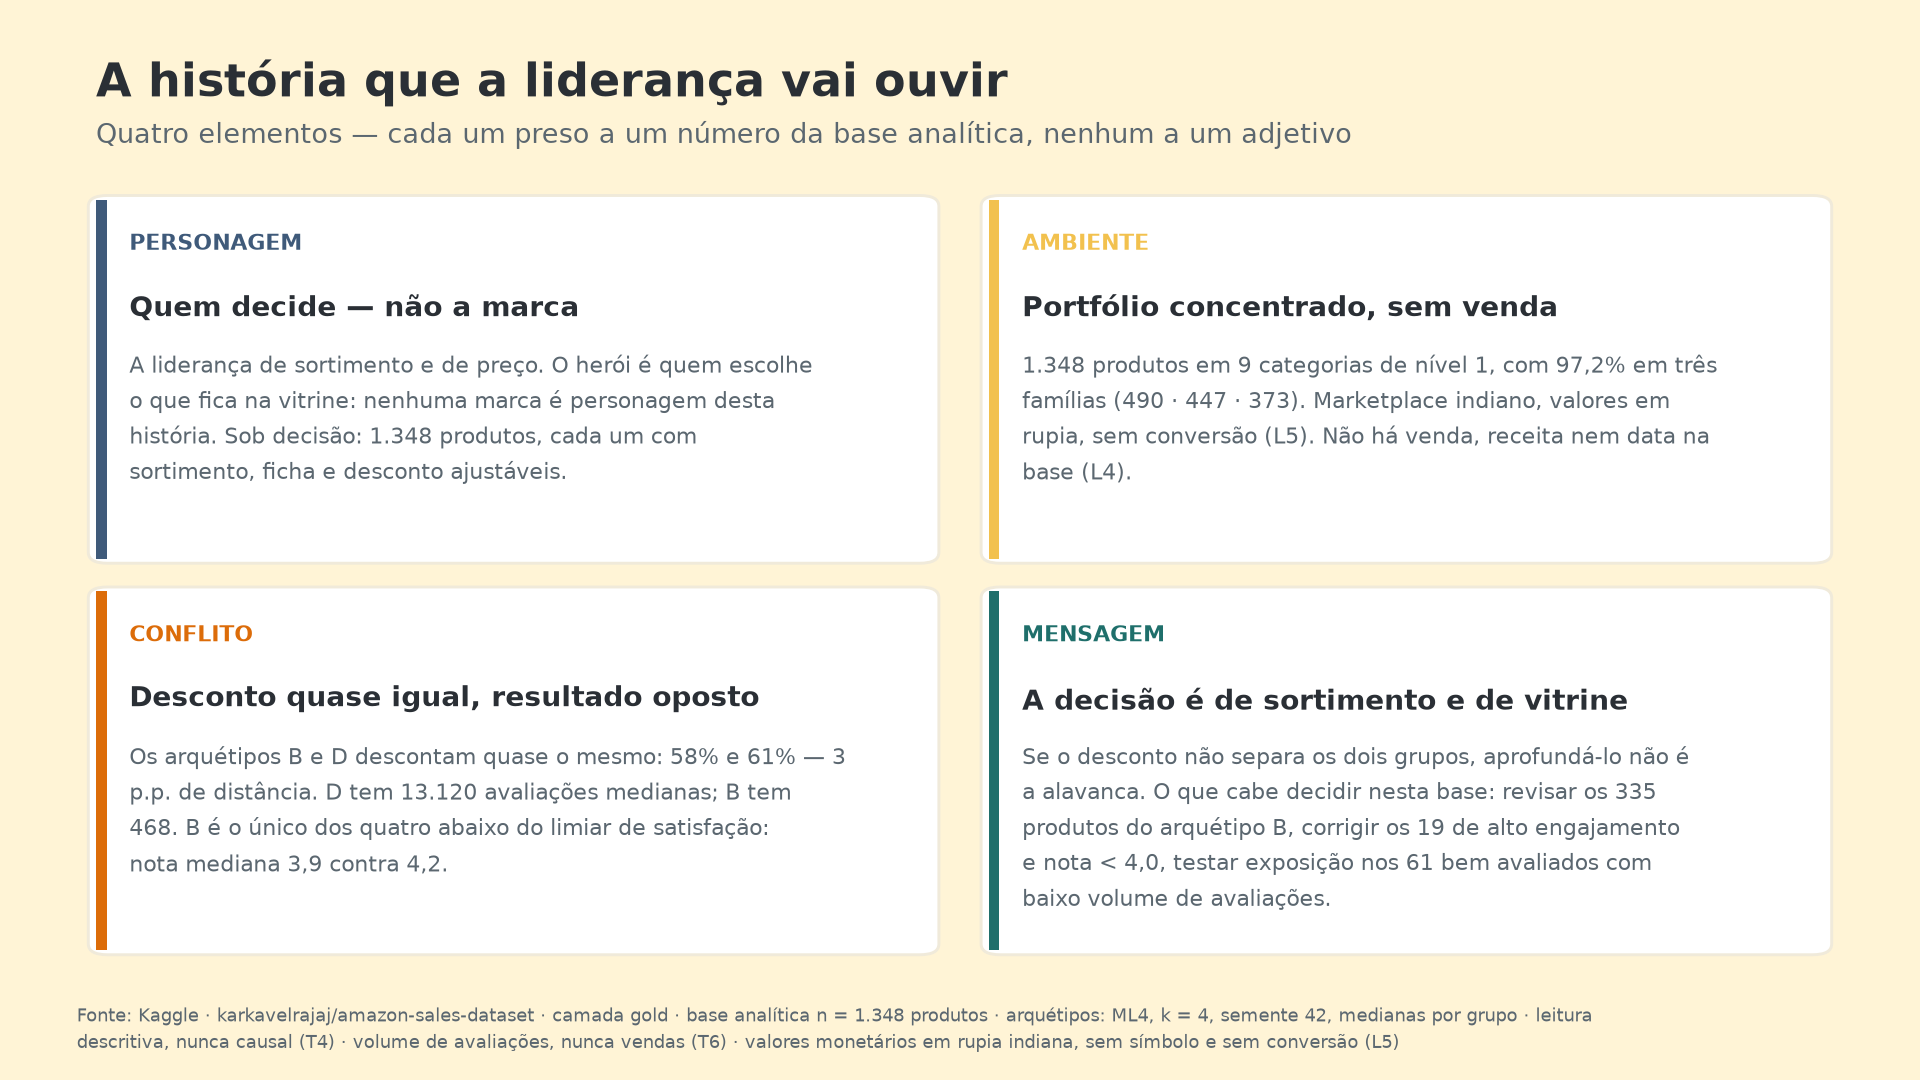

In [6]:
# Os quatro cartões têm a mesma altura: a maior das quatro medidas. Cartões de altura
# diferente lado a lado fazem o olho procurar hierarquia onde não existe.
elementos = [
    ("Personagem", "Quem decide — não a marca",
     "A liderança de sortimento e de preço. O herói é quem escolhe o que fica na vitrine: "
     f"nenhuma marca é personagem desta história. Sob decisão: {milhar(N)} produtos, cada um com "
     "sortimento, ficha e desconto ajustáveis.", AZUL),
    ("Ambiente", "Portfólio concentrado, sem venda",
     f"{milhar(N)} produtos em 9 categorias de nível 1, com "
     f"{virg(100 * acima.head(3).sum() / N, 1)}% em três famílias "
     f"({milhar(acima.iloc[0])} · {milhar(acima.iloc[1])} · {milhar(acima.iloc[2])}). "
     "Marketplace indiano, valores em rupia, sem conversão (L5). "
     "Não há venda, receita nem data na base (L4).", AMBAR),
    ("Conflito", "Desconto quase igual, resultado oposto",
     f"Os arquétipos B e D descontam quase o mesmo: {B.desconto:.0f}% e {D.desconto:.0f}% — "
     f"{DIST_DESCONTO:.0f} p.p. de distância. D tem {milhar(D.avaliacoes)} avaliações medianas; "
     f"B tem {milhar(B.avaliacoes)}. B é o único dos quatro abaixo do limiar de satisfação: "
     f"nota mediana {virg(B.nota, 1)} contra {virg(D.nota, 1)}.", LARANJA),
    ("Mensagem", "A decisão é de sortimento e de vitrine",
     "Se o desconto não separa os dois grupos, aprofundá-lo não é a alavanca. O que cabe decidir "
     f"nesta base: revisar os {milhar(B.n)} produtos do arquétipo B, corrigir os {n_q5} de alto "
     f"engajamento e nota < 4,0, testar exposição nos {n_q6_acionavel} bem avaliados com baixo volume "
     "de avaliações.", TEAL),
]

fig = plt.figure(figsize=SLIDE, facecolor=CANVAS)
fig.text(0.05, 0.945, "A história que a liderança vai ouvir", fontsize=22,
         fontweight="bold", color=TINTA, va="top")
fig.text(0.05, 0.888, "Quatro elementos — cada um preso a um número da base analítica, "
         "nenhum a um adjetivo", fontsize=13, color=SEC, va="top")

LARG = 0.435
ALTURA = max(medir_cartao(LARG, t, c, 13.5, 10.5)[0] for _, t, c, _ in elementos)
for i, (etiqueta, titulo, corpo, cor) in enumerate(elementos):
    x = 0.05 if i % 2 == 0 else 0.515
    topo = 0.815 if i < 2 else 0.815 - ALTURA - 0.03
    cartao(fig, x, topo, LARG, etiqueta, titulo, corpo, cor, altura=ALTURA)

rodape(fig, FONTE + f" · arquétipos: ML4, k = 4, semente {SEMENTE}, medianas por grupo · "
       "leitura descritiva, nunca causal (T4) · volume de avaliações, nunca vendas (T6) · "
       "valores monetários em rupia indiana, sem símbolo e sem conversão (L5)")
salva(fig, "fig_st_01_arco_narrativo.png")

## 6. Figura 2 — o ambiente

O ambiente responde a uma pergunta que a liderança faz antes de qualquer recomendação: *sobre o que,
exatamente, estamos falando?*

Duas leituras, lado a lado:

- **Onde está o portfólio.** As 5 categorias abaixo do piso aparecem **somadas em uma barra cinza e
  declaradas** — nunca ordenadas entre si (T2). Elas somam 7 produtos: ranqueá-las seria comparar
  ruído. Mostrar que existem, e que são residuais, é o que sustenta a frase "análise de categorias
  significa, na prática, três famílias mais uma no limite amostral" (L3).
- **Como a nota se distribui.** As três zonas — abaixo de 4,0, faixa intermediária e 4,3 ou mais —
  são os mesmos cortes que valem no `.pbix`. A cor separa as zonas; a linha tracejada marca o limiar.

A faixa de indicadores no topo usa **medianas**, não médias: a distribuição de preço e de volume é
fortemente assimétrica (máximo de 426.973 avaliações contra mediana de 4.740), e a média descreveria
um produto que não existe.

gravada: 02_results/images/fig_st_02_ambiente.png


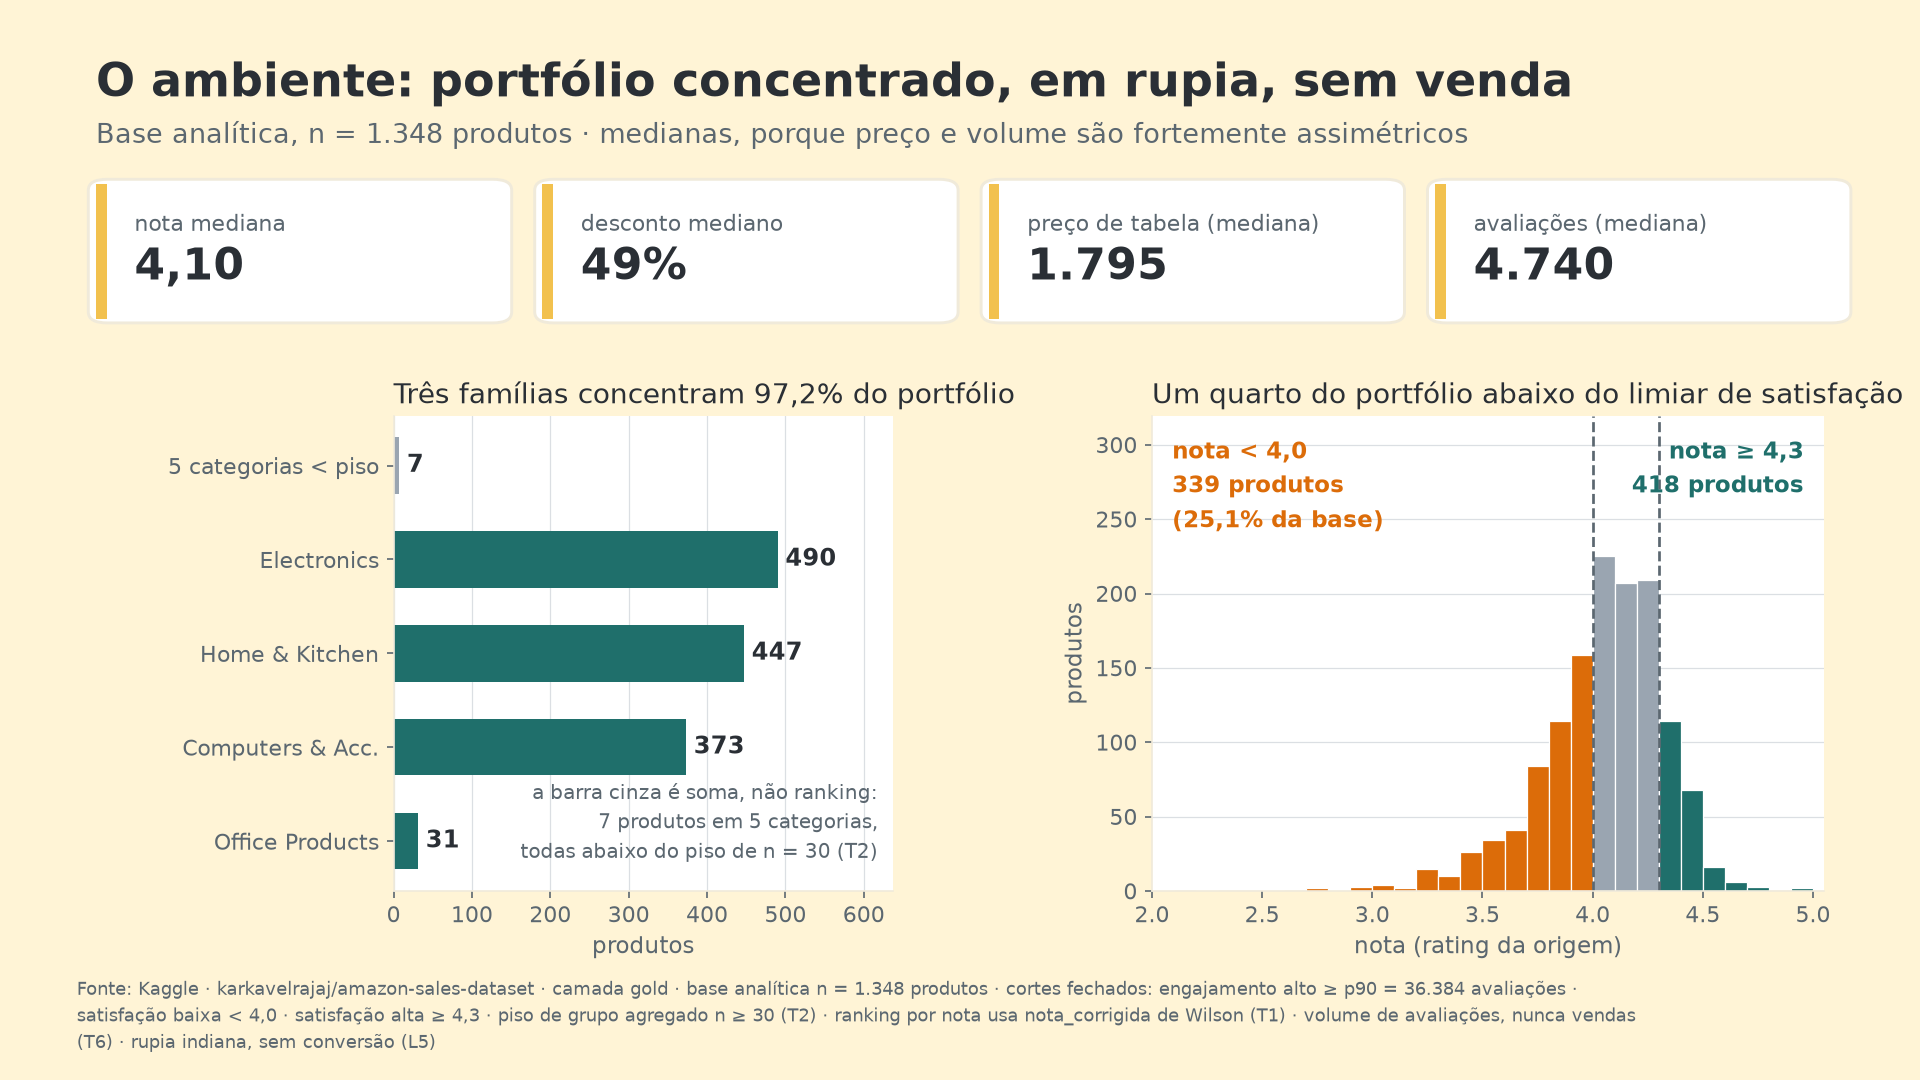

In [7]:
fig = plt.figure(figsize=SLIDE, facecolor=CANVAS)
fig.text(0.05, 0.945, "O ambiente: portfólio concentrado, em rupia, sem venda",
         fontsize=22, fontweight="bold", color=TINTA, va="top")
fig.text(0.05, 0.888, f"Base analítica, n = {milhar(N)} produtos · medianas, porque preço e volume "
         "são fortemente assimétricos", fontsize=13, color=SEC, va="top")

# --- faixa de indicadores ---
kpis = [("nota mediana", virg(gold.nota.median(), 2)),
        ("desconto mediano", f"{gold.desconto.median():.0f}%"),
        ("preço de tabela (mediana)", milhar(gold.preco_tab.median())),
        ("avaliações (mediana)", milhar(MEDIANA_AVAL))]
for i, (titulo, valor) in enumerate(kpis):
    x, y, larg, alt = 0.05 + i * 0.2325, 0.705, 0.2125, 0.125
    fig.add_artist(FancyBboxPatch((x, y), larg, alt,
                                  boxstyle="round,pad=0.004,rounding_size=0.010",
                                  transform=fig.transFigure, facecolor=CARD,
                                  edgecolor=DIVISOR, linewidth=1.4))
    fig.add_artist(Rectangle((x, y), 0.0055, alt, transform=fig.transFigure,
                             facecolor=AMBAR, edgecolor="none"))
    fig.text(x + 0.020, y + alt - 0.028, titulo, fontsize=10.5, color=SEC, va="top")
    fig.text(x + 0.020, y + alt - 0.058, valor, fontsize=21, fontweight="bold",
             color=TINTA, va="top")

# --- esquerda: categorias de nível 1 (T2 separa o que pode ser ranqueado) ---
eixo = fig.add_axes([0.205, 0.175, 0.26, 0.44])
CURTOS = {"Electronics": "Electronics", "Home&Kitchen": "Home & Kitchen",
          "Computers&Accessories": "Computers & Acc.", "OfficeProducts": "Office Products"}
nomes = [CURTOS.get(c, c) for c in acima.index[::-1]] + [f"{len(abaixo)} categorias < piso"]
valores = list(acima.values[::-1]) + [int(abaixo.sum())]
cores = [TEAL] * len(acima) + [CLARA]
checar_series(2)   # duas séries apenas: acima e abaixo do piso
barras = eixo.barh(nomes, valores, color=cores, height=0.6)
for barra, valor in zip(barras, valores):
    eixo.text(valor + 10, barra.get_y() + barra.get_height() / 2, milhar(valor),
              va="center", fontsize=11.5, color=TINTA, fontweight="bold")
eixo.set_xlim(0, max(valores) * 1.30)
eixo.set_xlabel("produtos", fontsize=11)
eixo.tick_params(labelsize=10.5)
eixo.set_title(f"Três famílias concentram {virg(100 * acima.head(3).sum() / N, 1)}% do portfólio",
               fontsize=13.5, loc="left")
eixo.grid(axis="y", visible=False)
eixo.text(0.97, 0.05, f"a barra cinza é soma, não ranking:\n{int(abaixo.sum())} produtos em "
          f"{len(abaixo)} categorias,\ntodas abaixo do piso de n = {PISO} (T2)",
          transform=eixo.transAxes, ha="right", va="bottom", fontsize=9.5, color=SEC,
          linespacing=1.5)

# --- direita: distribuição da nota, com os cortes operacionais ---
eixo2 = fig.add_axes([0.60, 0.175, 0.35, 0.44])
contagem, bordas, retangulos = eixo2.hist(gold.nota, bins=np.arange(2.0, 5.05, 0.1),
                                          edgecolor=CARD, linewidth=0.6)
for retangulo, borda in zip(retangulos, bordas[:-1]):
    retangulo.set_facecolor(LARANJA if borda < 3.999 else (TEAL if borda >= 4.299 else CLARA))
eixo2.axvline(4.0, color=SEC, ls="--", lw=1.3)
eixo2.axvline(4.3, color=SEC, ls="--", lw=1.3)
eixo2.text(0.03, 0.96, f"nota < 4,0\n{n_baixa} produtos\n({virg(pct_baixa, 1)}% da base)",
           transform=eixo2.transAxes, ha="left", va="top", fontsize=11,
           color=LARANJA, fontweight="bold", linespacing=1.5)
eixo2.text(0.97, 0.96, f"nota ≥ 4,3\n{n_alta} produtos", transform=eixo2.transAxes,
           ha="right", va="top", fontsize=11, color=TEAL, fontweight="bold", linespacing=1.5)
eixo2.set_xlim(2.0, 5.05)
eixo2.set_ylim(0, contagem.max() * 1.42)   # folga no topo: as anotações não cobrem barra
eixo2.set_xlabel("nota (rating da origem)", fontsize=11)
eixo2.set_ylabel("produtos", fontsize=11)
eixo2.tick_params(labelsize=10.5)
eixo2.set_title("Um quarto do portfólio abaixo do limiar de satisfação",
                fontsize=13.5, loc="left")
eixo2.grid(axis="x", visible=False)

rodape(fig, FONTE + f" · cortes fechados: engajamento alto ≥ p90 = {milhar(P90)} avaliações · "
       f"satisfação baixa < 4,0 · satisfação alta ≥ 4,3 · piso de grupo agregado n ≥ {PISO} (T2) · "
       "ranking por nota usa nota_corrigida de Wilson (T1) · volume de avaliações, nunca vendas "
       "(T6) · rupia indiana, sem conversão (L5)")
salva(fig, "fig_st_02_ambiente.png")

## 7. Figura 3 — o conflito

Esta é a figura central do vídeo. Ela precisa provar, sem narração, que **o desconto não separa os
dois grupos**.

A dispersão à esquerda mostra os 1.348 produtos, cada um no seu arquétipo, com o **volume de
avaliações em escala logarítmica** — sem o log, os 426.973 do extremo achatam todo o resto contra o
eixo e a figura não mostra nada. O `X` marca a **mediana de cada grupo**: é ali que se vê B e D
quase na mesma vertical de desconto e em alturas completamente diferentes. A e C ficam em segundo
plano, com transparência maior, porque o conflito é entre B e D — mas continuam na figura, porque
omiti-los daria a impressão de que o portfólio inteiro se divide em dois.

Os três painéis à direita fazem a comparação direta. A ordem é deliberada: primeiro o que é
**igual** (desconto), depois o que é **oposto** (volume e nota). É a sequência que a fala do vídeo
acompanha.

Quatro séries, dentro do limite de cinco da T9, com rótulo direto na legenda. E a ressalva que não
pode faltar quando esta figura aparece: os arquétipos são **convenção descritiva** — a silhueta de
0,234 diz que não há agrupamento natural nesta base.

gravada: 02_results/images/fig_st_03_conflito.png


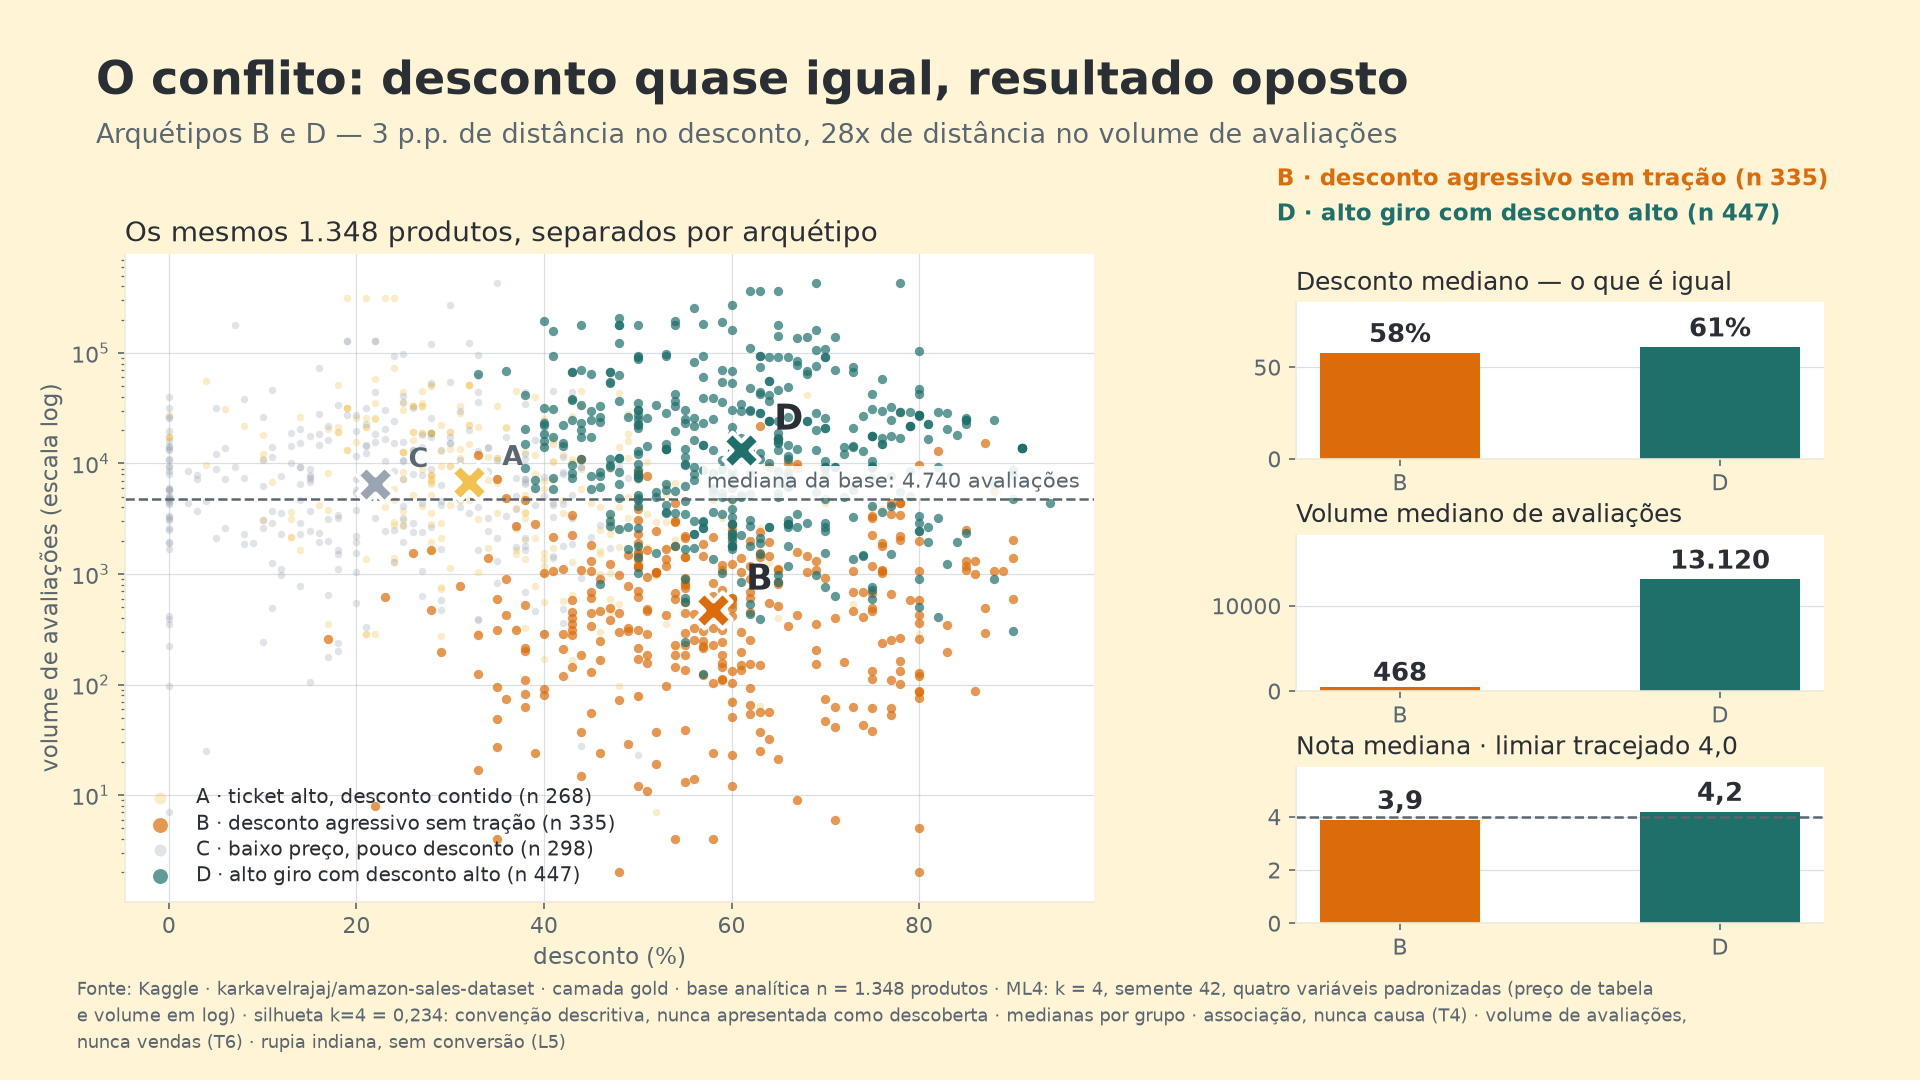

In [8]:
cor_arq = {"A": AMBAR, "B": LARANJA, "C": CLARA, "D": TEAL}
checar_series(len(cor_arq))

fig = plt.figure(figsize=SLIDE, facecolor=CANVAS)
fig.text(0.05, 0.945, "O conflito: desconto quase igual, resultado oposto",
         fontsize=22, fontweight="bold", color=TINTA, va="top")
fig.text(0.05, 0.888, f"Arquétipos B e D — {DIST_DESCONTO:.0f} p.p. de distância no desconto, "
         f"{RAZAO_VOLUME:.0f}x de distância no volume de avaliações",
         fontsize=13, color=SEC, va="top")

# --- dispersão: os 1.348 produtos, um ponto cada ---
eixo = fig.add_axes([0.065, 0.165, 0.505, 0.60])
desenhos = {}
for letra in ["A", "C", "B", "D"]:          # B e D por último: ficam à frente
    parte = gold[gold.arquetipo == letra]
    frente = letra in ("B", "D")
    desenhos[letra] = eixo.scatter(
        parte.desconto, parte.avaliacoes, s=20 if frente else 13, color=cor_arq[letra],
        alpha=0.70 if frente else 0.30, linewidths=0,
        label=f"{letra} · {NOMES_ARQ[letra].lower()} (n {int(arq.loc[letra, 'n'])})")
for letra in ["A", "B", "C", "D"]:
    linha = arq.loc[letra]
    eixo.scatter([linha.desconto], [linha.avaliacoes], marker="X", s=300,
                 color=cor_arq[letra], edgecolors=CARD, linewidth=2, zorder=5)
    destaque = letra in ("B", "D")
    eixo.annotate(letra, xy=(linha.desconto, linha.avaliacoes),
                  xytext=(16, 10 if destaque else 8), textcoords="offset points",
                  fontsize=17 if destaque else 13, fontweight="bold",
                  color=TINTA if destaque else SEC, zorder=6)
eixo.axhline(MEDIANA_AVAL, color=SEC, ls="--", lw=1.2)
eixo.text(0.985, MEDIANA_AVAL * 1.15, f"mediana da base: {milhar(MEDIANA_AVAL)} avaliações",
          transform=eixo.get_yaxis_transform(), ha="right", va="bottom", fontsize=10, color=SEC,
          bbox=dict(facecolor=CARD, edgecolor="none", alpha=0.88, pad=2.5))
eixo.set_yscale("log")
eixo.set_xlabel("desconto (%)", fontsize=11)
eixo.set_ylabel("volume de avaliações (escala log)", fontsize=11)
eixo.tick_params(labelsize=10.5)
eixo.set_title(f"Os mesmos {milhar(N)} produtos, separados por arquétipo",
               fontsize=13.5, loc="left")
eixo.legend([desenhos[l] for l in "ABCD"],
            [desenhos[l].get_label() for l in "ABCD"],
            loc="lower left", fontsize=9.5, labelspacing=0.3, borderpad=0.3,
            markerscale=1.6)

# --- três comparações diretas B x D ---
fig.text(0.665, 0.845, f"B · {NOMES_ARQ['B'].lower()} (n {int(B.n)})", fontsize=11,
         color=LARANJA, fontweight="bold", va="top")
fig.text(0.665, 0.812, f"D · {NOMES_ARQ['D'].lower()} (n {int(D.n)})", fontsize=11,
         color=TEAL, fontweight="bold", va="top")
medidas = [("Desconto mediano — o que é igual", "desconto", lambda v: f"{v:.0f}%", None),
           ("Volume mediano de avaliações", "avaliacoes", milhar, None),
           ("Nota mediana · limiar tracejado 4,0", "nota", lambda v: virg(v, 1), 4.0)]
for i, (titulo, coluna, formata, limiar) in enumerate(medidas):
    eixo_i = fig.add_axes([0.675, 0.575 - i * 0.215, 0.275, 0.145])
    valores = [B[coluna], D[coluna]]
    barras = eixo_i.bar(["B", "D"], valores, color=[LARANJA, TEAL], width=0.5)
    for barra, valor in zip(barras, valores):
        eixo_i.text(barra.get_x() + barra.get_width() / 2, valor * 1.04, formata(valor),
                    ha="center", va="bottom", fontsize=12.5, color=TINTA, fontweight="bold")
    eixo_i.set_title(titulo, fontsize=12, loc="left")
    eixo_i.set_ylim(0, max(valores) * 1.40)
    eixo_i.tick_params(labelsize=10.5)
    eixo_i.grid(axis="x", visible=False)
    if limiar:
        # A linha do limiar é explicada no título do painel: qualquer legenda dentro
        # dele cairia sobre o rótulo de uma das duas barras.
        eixo_i.axhline(limiar, color=SEC, ls="--", lw=1.2)

rodape(fig, FONTE + f" · ML4: k = 4, semente {SEMENTE}, quatro variáveis padronizadas (preço de "
       f"tabela e volume em log) · silhueta k=4 = {virg(silhuetas[4], 3)}: convenção descritiva, "
       "nunca apresentada como descoberta · medianas por grupo · associação, nunca causa (T4) · "
       "volume de avaliações, nunca vendas (T6) · rupia indiana, sem conversão (L5)")
salva(fig, "fig_st_03_conflito.png")

## 8. Figura 4 — a mensagem

A última figura responde à pergunta com que o vídeo encerra: *quais são as principais mensagens que
a liderança deve levar?*

Três decisões, cada uma com o **n** que ela alcança — e nenhuma expressa em receita ou volume
vendido, porque a base não tem variável de venda (L4). A terceira usa a **lista acionável** — os 61
que continuam com nota ≥ 4,3 depois da correção de Wilson (T1), não o funil de 187 — e o rótulo
fechado na decisão D-1 (24/09/2026): *bem avaliados com baixo volume de avaliações*. Volume de
avaliações é **proxy declarado** de exposição; escrever "baixa visibilidade" afirmaria mais do que
foi medido, e é vedado em visual, slide ou frame.

Embaixo, as quatro associações medidas — a evidência de que **o desconto não é a alavanca**. O
p-valor fica junto do nome do par, e a magnitude na própria barra: as duas informações aparecem
sempre juntas (T5), e nenhuma é lida como causa (T4). O par preço × nota entra justamente por ser
**não significativo**: uma hipótese comum descartada vale tanto quanto uma confirmada, e omiti-la
seria escolher o que mostrar.

Ao lado, o que esta base **não** permite dizer. É o bloco que protege a análise na primeira pergunta
difícil.

gravada: 02_results/images/fig_st_04_mensagem.png


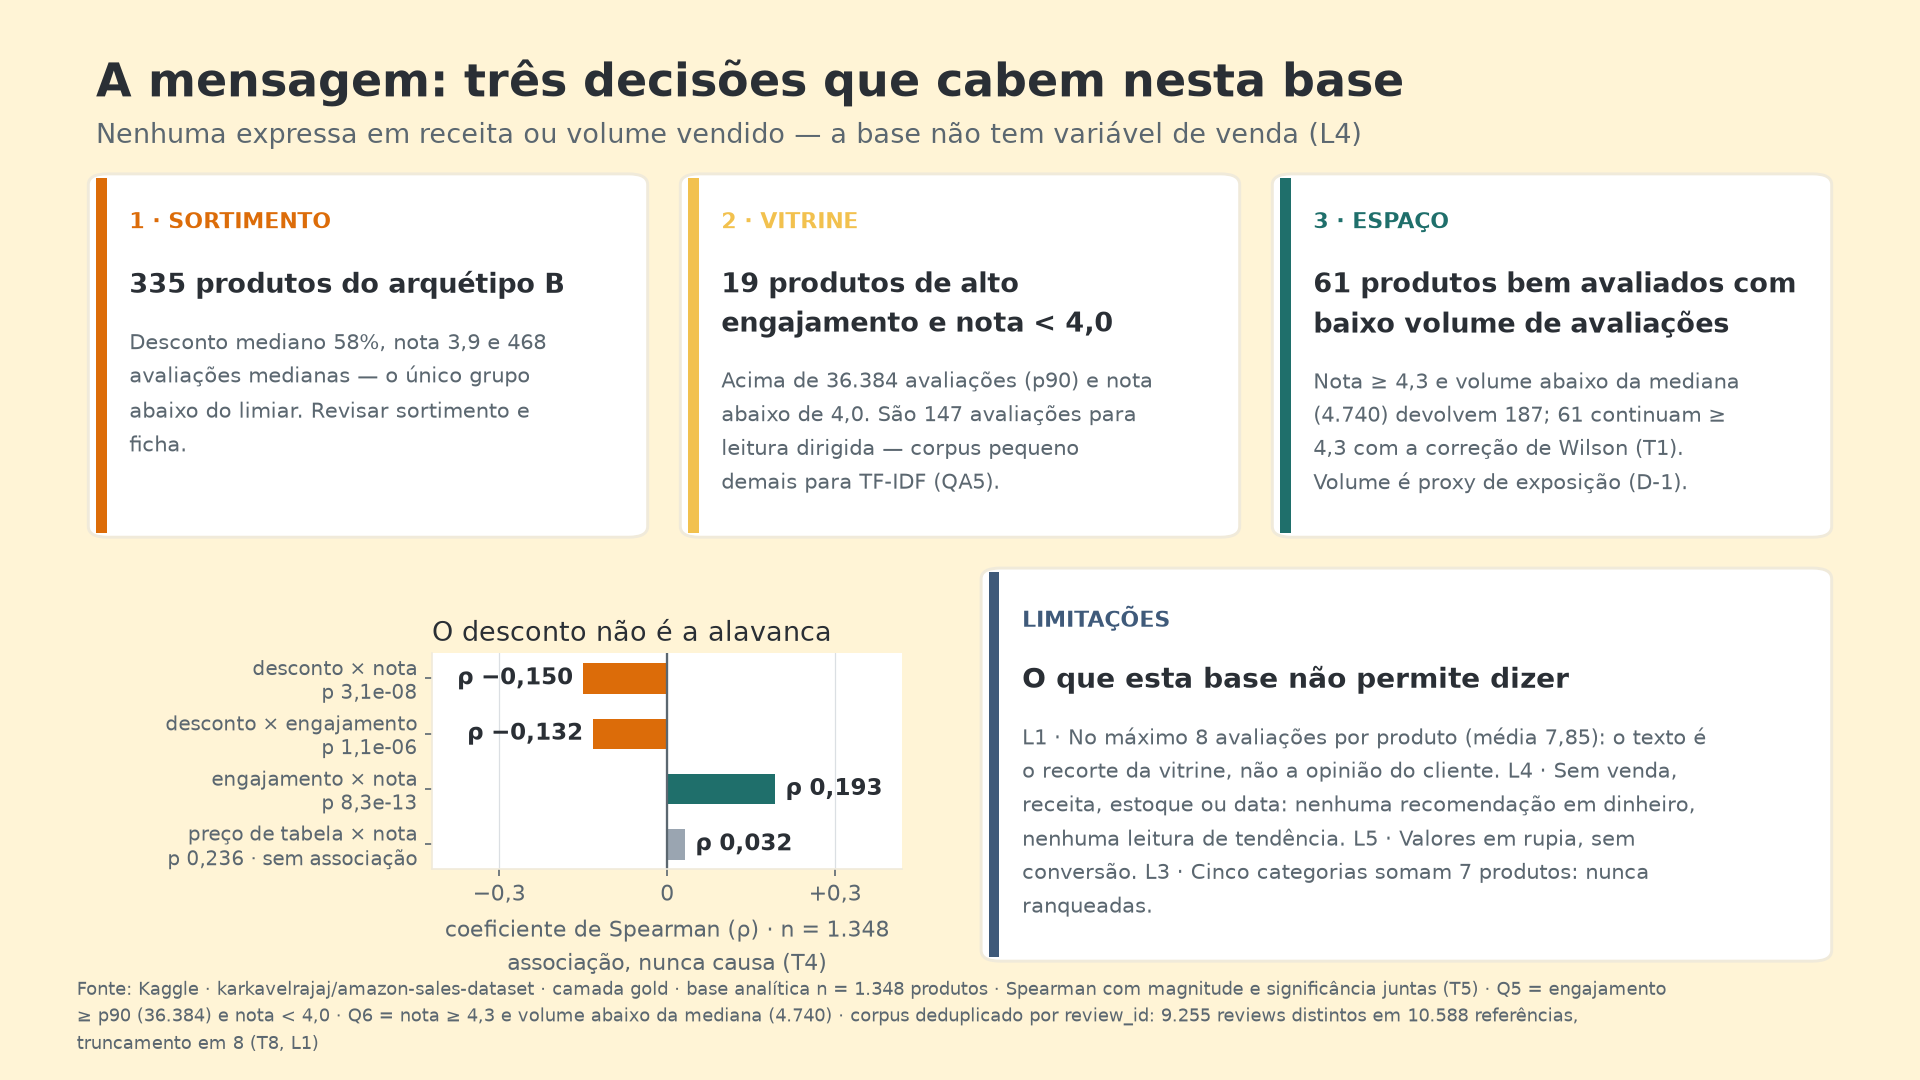

In [9]:
fig = plt.figure(figsize=SLIDE, facecolor=CANVAS)
fig.text(0.05, 0.945, "A mensagem: três decisões que cabem nesta base",
         fontsize=22, fontweight="bold", color=TINTA, va="top")
fig.text(0.05, 0.888, "Nenhuma expressa em receita ou volume vendido — a base não tem variável de "
         "venda (L4)", fontsize=13, color=SEC, va="top")

decisoes = [
    ("1 · Sortimento", f"{milhar(B.n)} produtos do arquétipo B",
     f"Desconto mediano {B.desconto:.0f}%, nota {virg(B.nota, 1)} e {milhar(B.avaliacoes)} "
     "avaliações medianas — o único grupo abaixo do limiar. Revisar sortimento e ficha.", LARANJA),
    ("2 · Vitrine", f"{n_q5} produtos de alto engajamento e nota < 4,0",
     f"Acima de {milhar(P90)} avaliações (p90) e nota abaixo de 4,0. São {AVAL_Q5} avaliações "
     "para leitura dirigida — corpus pequeno demais para TF-IDF (QA5).", AMBAR),
    ("3 · Espaço", f"{n_q6_acionavel} produtos bem avaliados com baixo volume de avaliações",
     f"Nota ≥ 4,3 e volume abaixo da mediana ({milhar(MEDIANA_AVAL)}) devolvem {n_q6}; "
     f"{n_q6_acionavel} continuam ≥ 4,3 com a correção de Wilson (T1). Volume é proxy de exposição (D-1).", TEAL),
]
# Três cartões entre as margens 0,05 e 0,95 — a mesma borda direita do cartão de limitações.
# (Com largura 0,30 e passo 0,325, o terceiro terminava em 1,0 e era cortado pela borda da tela.)
VAO_D = 0.025
LARG_D = (0.90 - 2 * VAO_D) / 3
ALTURA_D = max(medir_cartao(LARG_D, t, c, 13, 10)[0] for _, t, c, _ in decisoes)
for i, (etiqueta, titulo, corpo, cor) in enumerate(decisoes):
    cartao(fig, 0.05 + i * (LARG_D + VAO_D), 0.835, LARG_D, etiqueta, titulo, corpo, cor,
           fs_titulo=13, fs_corpo=10, altura=ALTURA_D)

# --- associações medidas: magnitude na barra, significância no rótulo do eixo ---
eixo = fig.add_axes([0.225, 0.195, 0.245, 0.20])
dados = assoc.iloc[::-1]
cores = [(CLARA if p >= 0.05 else (TEAL if r > 0 else LARANJA))
         for r, p in zip(dados.rho, dados.p)]
checar_series(3)   # negativa significativa · positiva significativa · sem associação
rotulos = [f"{par}\np {pval(p)}" + (" · sem associação" if p >= 0.05 else "")
           for par, p in zip(dados.par, dados.p)]
barras = eixo.barh(rotulos, dados.rho, color=cores, height=0.55)
for barra, r in zip(barras, dados.rho):
    eixo.text(r + (0.018 if r > 0 else -0.018), barra.get_y() + barra.get_height() / 2,
              f"ρ {virg(r, 3).replace('-', '−')}", va="center",
              ha="left" if r > 0 else "right", fontsize=11, color=TINTA, fontweight="bold")
eixo.axvline(0, color=SEC, lw=1.1)
eixo.set_xlim(-0.42, 0.42)
eixo.set_xticks([-0.3, 0.0, 0.3])
eixo.set_xticklabels(["−0,3", "0", "+0,3"])
eixo.tick_params(axis="y", labelsize=9.5)
eixo.tick_params(axis="x", labelsize=10.5)
# Título curto de propósito: um título longo avançaria sobre o cartão de limitações.
eixo.set_xlabel("coeficiente de Spearman (ρ) · n = " + milhar(N)
                + "\nassociação, nunca causa (T4)", fontsize=10.5, linespacing=1.5)
eixo.set_title("O desconto não é a alavanca", fontsize=13, loc="left")
eixo.grid(axis="y", visible=False)

cartao(fig, 0.515, 0.47, 0.435, "Limitações", "O que esta base não permite dizer",
       f"L1 · No máximo 8 avaliações por produto (média {virg(TRUNC_MEDIA)}): o texto é o recorte "
       "da vitrine, não a opinião do cliente. L4 · Sem venda, receita, estoque ou data: nenhuma "
       "recomendação em dinheiro, nenhuma leitura de tendência. L5 · Valores em rupia, sem "
       "conversão. L3 · Cinco categorias somam 7 produtos: nunca ranqueadas.",
       AZUL, fs_titulo=13.5, fs_corpo=10)

rodape(fig, FONTE + " · Spearman com magnitude e significância juntas (T5) · "
       f"Q5 = engajamento ≥ p90 ({milhar(P90)}) e nota < 4,0 · Q6 = nota ≥ 4,3 e volume abaixo da "
       f"mediana ({milhar(MEDIANA_AVAL)}) · corpus deduplicado por review_id: "
       f"{milhar(DISTINTOS)} reviews distintos em {milhar(REFS)} referências, truncamento em "
       f"{TRUNC_MAX} (T8, L1)")
salva(fig, "fig_st_04_mensagem.png")

## 9. Validação final — reconciliação com o material

Nada do que foi desenhado acima vale se um número da figura divergir do material do projeto. Esta
célula recalcula cada valor citado nas quatro figuras e compara com a **base factual**
(`method/definitions/base_factual_e_bases_de_calculo.md`) e com o **registro de ML**
(`method/definitions/registro_machine_learning.md`).

A comparação é de igualdade estrita e **levanta exceção** em caso de divergência: um notebook que
imprime "divergente" e segue adiante não protege ninguém.

Também conferimos que as figuras `fig01`–`fig13`, geradas por outros notebooks, **continuam
intactas** — o prefixo `fig_st_` existe exatamente para isso.

In [10]:
import re

esperado = {
    "bronze — linhas": (N_BRONZE if N_BRONZE is not None else 1465, 1465),
    "silver — produtos": (len(silver), 1351),
    "nota válida": (int(silver.nota.notna().sum()), 1350),
    "engajamento válido": (int(silver.avaliacoes.notna().sum()), 1349),
    "gold — base analítica": (N, 1348),
    "p90 de avaliações": (int(P90), 36384),
    "mediana de avaliações": (int(MEDIANA_AVAL), 4740),
    "nota < 4,0": (n_baixa, 339),
    "nota < 4,0 (%)": (round(pct_baixa, 1), 25.1),
    "nota >= 4,3": (n_alta, 418),
    "Q5 — alto engajamento e nota < 4,0": (n_q5, 19),
    "Q6 — nota >= 4,3 e volume < mediana": (n_q6, 187),
    "Q6 — lista acionável (Wilson >= 4,3)": (n_q6_acionavel, 61),
    "Pareto 80%": (n_pareto, 306),
    "Pareto 80% (%)": (round(100 * n_pareto / N, 1), 22.7),
    "categorias n1 acima do piso": (len(acima), 4),
    "produtos fora do piso (n1)": (int(abaixo.sum()), 7),
    "Electronics": (int(cat1["Electronics"]), 490),
    "Home&Kitchen": (int(cat1["Home&Kitchen"]), 447),
    "Computers&Accessories": (int(cat1["Computers&Accessories"]), 373),
    "OfficeProducts": (int(cat1["OfficeProducts"]), 31),
    "subcategorias n2 acima do piso": (len(sub_acima), 8),
    "cobertura das subcategorias (%)": (round(100 * sub_acima.sum() / N, 1), 88.3),
    "silhueta k=3": (round(silhuetas[3], 3), 0.215),
    "silhueta k=4": (round(silhuetas[4], 3), 0.234),
    "silhueta k=5": (round(silhuetas[5], 3), 0.237),
    "arquétipo A — n": (int(arq.loc["A", "n"]), 268),
    "arquétipo B — n": (int(arq.loc["B", "n"]), 335),
    "arquétipo C — n": (int(arq.loc["C", "n"]), 298),
    "arquétipo D — n": (int(arq.loc["D", "n"]), 447),
    "B — desconto mediano": (int(B.desconto), 58),
    "D — desconto mediano": (int(D.desconto), 61),
    "B — avaliações medianas": (int(B.avaliacoes), 468),
    "D — avaliações medianas": (int(D.avaliacoes), 13120),
    "B — nota mediana": (round(B.nota, 1), 3.9),
    "D — nota mediana": (round(D.nota, 1), 4.2),
    "corpus — referências": (REFS, 10588),
    "corpus — review_id distintos": (DISTINTOS, 9255),
    "corpus — repetidas": (REPETIDAS, 1333),
    "corpus — reviews.csv": (len(reviews), 9255),
    "truncamento — média": (round(TRUNC_MEDIA, 2), 7.85),
    "truncamento — máximo": (TRUNC_MAX, 8),
    "avaliações nos 19 de Q5": (AVAL_Q5, 147),
    "ρ desconto × nota": (round(float(assoc.loc[0, "rho"]), 3), -0.150),
    "ρ desconto × engajamento": (round(float(assoc.loc[1, "rho"]), 3), -0.132),
    "ρ engajamento × nota": (round(float(assoc.loc[2, "rho"]), 3), 0.193),
    "ρ preço de tabela × nota": (round(float(assoc.loc[3, "rho"]), 3), 0.032),
}

recon = pd.DataFrame([{"indicador": k, "medido": m, "material": e, "confere": m == e}
                      for k, (m, e) in esperado.items()])

# Figuras: as quatro desta entrega existem; as treze de fig01 a fig13 continuam intactas.
novas = ["fig_st_01_arco_narrativo.png", "fig_st_02_ambiente.png",
         "fig_st_03_conflito.png", "fig_st_04_mensagem.png"]
for arquivo in novas:
    recon.loc[len(recon)] = {"indicador": f"figura gerada: {arquivo}",
                             "medido": os.path.exists(os.path.join(IMG, arquivo)),
                             "material": True, "confere": os.path.exists(os.path.join(IMG, arquivo))}
# Contagem por nome, não por total do diretório: outros notebooks do projeto também
# gravam aqui, e um total fixo quebraria por motivo alheio a esta entrega.
anteriores = sorted(f for f in os.listdir(IMG)
                    if re.fullmatch(r"fig(0[1-9]|1[0-3])_.+\.png", f))
recon.loc[len(recon)] = {"indicador": "figuras fig01–fig13 preservadas",
                         "medido": len(anteriores), "material": 13,
                         "confere": len(anteriores) == 13}

pd.set_option("display.max_rows", None, "display.width", 140)
display(recon)

divergencias = recon[~recon.confere]
print(f"\n{len(recon) - len(divergencias)} de {len(recon)} indicadores conferem com o material.")
print("Reconciliação das bases: "
      f"{milhar(N_BRONZE if N_BRONZE else 1465)} -> {milhar(len(silver))} -> 1.350 -> 1.349 -> "
      f"{milhar(N)}")
print("Nota de precisão: o p-valor de desconto × nota sai como "
      f"{pval(float(assoc.loc[0, 'p']))}; é o que a base factual publica. Divergência eventual seria de "
      "arredondamento na última casa e não altera a leitura (T5: ρ pequeno e significativo).")
if len(divergencias):
    display(divergencias)
    raise AssertionError(f"{len(divergencias)} indicador(es) divergem do material — "
                         "a figura está errada, não o material.")
print("\nValidação concluída: as quatro figuras fig_st_ reproduzem os números do projeto.")

,indicador,medido,material,confere
0,bronze — linhas,1465.000,1465.000,True
1,silver — produtos,1351.000,1351.000,True
2,nota válida,1350.000,1350.000,True
3,engajamento válido,1349.000,1349.000,True
4,gold — base analítica,1348.000,1348.000,True
5,p90 de avaliações,36384.000,36384.000,True
6,mediana de avaliações,4740.000,4740.000,True
7,"nota < 4,0",339.000,339.000,True
8,"nota < 4,0 (%)",25.100,25.100,True
9,"nota >= 4,3",418.000,418.000,True



52 de 52 indicadores conferem com o material.
Reconciliação das bases: 1.465 -> 1.351 -> 1.350 -> 1.349 -> 1.348
Nota de precisão: o p-valor de desconto × nota sai como 3,1e-08; é o que a base factual publica. Divergência eventual seria de arredondamento na última casa e não altera a leitura (T5: ρ pequeno e significativo).

Validação concluída: as quatro figuras fig_st_ reproduzem os números do projeto.


### Checklist de publicação (T1–T9)

| Regra | Como foi cumprida nestas quatro figuras |
|---|---|
| **T1** | nenhum ranking por nota é desenhado aqui; onde a nota aparece, é **mediana de grupo** com o *n* ao lado, e o rodapé declara que ranking usa `nota_corrigida` (Wilson) |
| **T2** | as 5 categorias abaixo do piso aparecem **somadas em uma barra declarada**, nunca ordenadas; as listas de Q5 e Q6 são nominais — exceção prevista, com o *n* exibido |
| **T3** | as quatro figuras trazem fonte, base, *n* e limiares no rodapé |
| **T4** | nenhuma frase afirma causa: "descontam quase o mesmo e divergem no resto", "associação, nunca causa" |
| **T5** | as quatro associações trazem ρ e p lado a lado, inclusive a **não significativa** |
| **T6** | o eixo, os rótulos e os rodapés dizem **volume de avaliações** — nunca vendas, receita ou demanda |
| **T7** | verificado por asserção: `user_id` e `user_name` não existem nas camadas lidas |
| **T8** | o corpus declara a unidade, deduplica por `review_id` (10.588 → 9.255) e cita o truncamento em 8 |
| **T9** | `aplicar()` na primeira célula, tokens nomeados, `checar_series()` em cada visual, **máximo de 4 séries** |
| **L5** | todo valor monetário sai **sem símbolo**, em rupia indiana, sem conversão |

### Onde cada figura entra

| Figura | `.pbix` | Vídeo |
|---|---|---|
| `fig_st_01_arco_narrativo` | abertura da página de Recomendações | bloco 1 — contexto do problema |
| `fig_st_02_ambiente` | Visão Executiva | blocos 1 e 2 — contexto e principais indicadores |
| `fig_st_03_conflito` | Produtos e Categorias | bloco 3 — principais insights (**figura central**) |
| `fig_st_04_mensagem` | Recomendações | blocos 6 e 7 — recomendações e conclusão executiva |